# Notebook B — Train from the numbers stored on Google Drive

Run **Notebook A first**. This notebook loads `meta.csv` and `emb_all.npy` from Drive and:
1. Builds patient-level train / val / test splits (the official NIH test list stays untouched).
2. Trains fast models on the 1024-number embeddings: **linear probe, MLP, unsupervised kNN**, plus the **age/sex/view confound baseline**, with **patient-clustered bootstrap CIs and paired tests**.
3. Draws a **data-size scaling curve** (does more data actually help?).
4. Calibrates the best model (temperature scaling, isotonic) and compares a **Bayesian Network** layer against those baselines.
5. **Optional** (`RUN_FINETUNE = True`): fine-tunes DenseNet-121 on the cached image arrays from Drive and compares it with the embedding models.

Honest limits: one dataset, noisy NLP-mined labels, ImageNet-pretrained embeddings, no external validation.

In [1]:
!pip install -q pgmpy scikit-learn scipy

## 0. Configuration

In [9]:
import os, time, math, json, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
warnings.filterwarnings("ignore")

# ------------------------- CONFIG -------------------------
# Ensure this matches the folder name used in Notebook A
WORK       = "/content/drive/MyDrive/hybrid_pgm_data"      # Automatically detected correct folder name
SIZES      = [5000, 10000, 20000, 40000]                   # training-set sizes for the scaling curve (the full train set is added)
HEAD_SEEDS = [0, 1, 2]                                     # heads trained with each seed; logits are averaged
N_BOOT     = 1000
N_BOOT_SCALE = 200
RUN_FINETUNE = False                                       # True = also fine-tune DenseNet-121 on the cached image arrays
FT_TRAIN_IMG, FT_VAL_IMG = 16000, 2000
FT_EPOCHS, FT_BATCH, FT_LR, FT_WD = 8, 16, 2e-4, 1e-4          # use FT_BATCH = 16 since the images are 512 px
# -----------------------------------------------------------
from google.colab import drive
drive.mount("/content/drive")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print("Device:", device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda


In [8]:
import os

def find_manifest(search_path="/content/drive"):
    print("Searching for 'manifest.json' in Google Drive...")
    matches = []
    for root, dirs, files in os.walk(search_path):
        if "manifest.json" in files:
            full_path = os.path.join(root, "manifest.json")
            # filter out common false positives if any
            if "hybrid_pgm" in root or "data" in root:
                matches.append(root)
    return matches

paths = find_manifest()
if paths:
    print(f"\nSuccess! Found manifest.json in the following folder(s):")
    for p in paths:
        print(f"-> {p}")
    # Update WORK to the first match found
    WORK = paths[0]
    print(f"\nUpdated variable WORK = '{WORK}'")
else:
    print("\nCould not find 'manifest.json' in Google Drive. Please double check that Notebook A has finished running.")

Searching for 'manifest.json' in Google Drive...

Success! Found manifest.json in the following folder(s):
-> /content/drive/MyDrive/hybrid_pgm_data

Updated variable WORK = '/content/drive/MyDrive/hybrid_pgm_data'


## 1. Load the numbers from Drive and build patient-level splits

In [10]:
manifest = json.load(open(f"{WORK}/manifest.json")); print(manifest)
meta = pd.read_csv(f"{WORK}/meta.csv")
emb = np.load(f"{WORK}/emb_all.npy"); assert len(emb) == len(meta)
X_all = emb.astype(np.float32); y_all = (~meta.is_normal.values).astype(int); RES = manifest["res"]

rng = np.random.default_rng(0)
tvm = (meta.split_official == "trainval").values
pats = rng.permutation(meta[tvm].patient.unique()); n_val = int(0.10 * len(pats))
va_p = set(pats[:n_val]); pat_order = pats[n_val:]                      # pat_order gives nested training subsets
meta["split"] = np.where(~tvm, "test", np.where(meta.patient.isin(va_p), "val", "train"))
P = {s: set(meta[meta.split == s].patient) for s in ["train", "val", "test"]}
assert not (P["train"] & P["val"]) and not (P["train"] & P["test"]) and not (P["val"] & P["test"]), "patient leakage!"
print("Patient-level split verified: no patient appears in two splits.")
itr, iva, ite = [np.where(meta.split.values == s)[0] for s in ["train", "val", "test"]]
tr, val, te = meta.iloc[itr].reset_index(drop=True), meta.iloc[iva].reset_index(drop=True), meta.iloc[ite].reset_index(drop=True)
y_tr, y_val, y_te = y_all[itr], y_all[iva], y_all[ite]
display(pd.DataFrame({n: {"images": len(d), "patients": d.patient.nunique(), "abnormal rate": round(float((~d.is_normal).mean()), 3),
                          "PA share": round(float((d.view == "PA").mean()), 3)} for n, d in [("train", tr), ("val", val), ("test", te)]}).T)

cnt_tr = tr.groupby("patient").size()
def train_idx_for(n_img):
    chosen, tot = set(), 0
    for p in pat_order:
        if tot >= n_img: break
        chosen.add(p); tot += int(cnt_tr[p])
    return np.where((meta.split.values == "train") & meta.patient.isin(chosen).values)[0]

{'n': 112120, 'res': 512, 'shard': 4096, 'n_shards': 28, 'backbone': 'densenet121-imagenet1k-v1 (global-average-pooled, 1024-d, FP16)', 'emb_dim': 1024, 'emb_dtype': 'float16', 'save_images': False, 'data_source': 'full', 'clahe': True, 'unreadable_images': 0, 'timestamp': '2026-10-24 05:28:34 UTC'}
Patient-level split verified: no patient appears in two splits.


,images,patients,abnormal rate,PA share
train,78147.0,25208.0,0.416,0.648
val,8377.0,2800.0,0.420,0.670
test,25596.0,2797.0,0.615,0.434


## 2. Helpers: bootstrap CIs, calibration, and a fast GPU training head

In [11]:
def _groups(groups):
    codes, uniq = pd.factorize(groups); return [np.where(codes == i)[0] for i in range(len(uniq))]

def boot_auc(y, groups, scores, n_boot=N_BOOT, seed=0):
    y = np.asarray(y); idx_by = _groups(groups); rng_ = np.random.default_rng(seed); boots = {k: [] for k in scores}
    for _ in range(n_boot):
        ii = np.concatenate([idx_by[p] for p in rng_.integers(0, len(idx_by), len(idx_by))]); yy = y[ii]
        if yy.min() == yy.max(): continue
        for k, s in scores.items(): boots[k].append(roc_auc_score(yy, s[ii]))
    return pd.DataFrame([{"Method": k, "AUROC": roc_auc_score(y, s), "CI_low": np.percentile(boots[k], 2.5),
                          "CI_high": np.percentile(boots[k], 97.5)} for k, s in scores.items()])

def paired_diff(y, groups, s_a, s_b, n_boot=N_BOOT, seed=0):
    y = np.asarray(y); idx_by = _groups(groups); rng_ = np.random.default_rng(seed); d = []
    for _ in range(n_boot):
        ii = np.concatenate([idx_by[p] for p in rng_.integers(0, len(idx_by), len(idx_by))]); yy = y[ii]
        if yy.min() == yy.max(): continue
        d.append(roc_auc_score(yy, s_a[ii]) - roc_auc_score(yy, s_b[ii]))
    lo, hi = np.percentile(d, [2.5, 97.5]); return roc_auc_score(y, s_a) - roc_auc_score(y, s_b), lo, hi

def brier_ece(p, y, bins=10):
    p = np.asarray(p, float); y = np.asarray(y, float); edges = np.linspace(0, 1, bins + 1); ece = 0.0
    for i in range(bins):
        hi = (p < edges[i+1]) if i < bins - 1 else (p <= edges[i+1]); m = (p >= edges[i]) & hi
        if m.any(): ece += m.mean() * abs(p[m].mean() - y[m].mean())
    return float(np.mean((p - y) ** 2)), float(ece)

def sigmoid(z): return 1.0 / (1.0 + np.exp(-z))

def train_head(Xtr, ytr, Xva, yva, hidden=0, epochs=40, lr=1e-3, wd=1e-3, drop=0.3, bs=1024, seed=0, patience=6):
    torch.manual_seed(seed); d = Xtr.shape[1]
    net = nn.Linear(d, 1) if hidden == 0 else nn.Sequential(nn.Linear(d, hidden), nn.ReLU(), nn.Dropout(drop),
                                                           nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Dropout(drop), nn.Linear(hidden // 2, 1))
    net = net.to(device); opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=wd)
    Xt, yt, Xv = torch.from_numpy(Xtr).to(device), torch.from_numpy(ytr).float().to(device), torch.from_numpy(Xva).to(device)
    best, bad = (-1.0, None), 0
    for ep in range(epochs):
        net.train(); perm = torch.randperm(len(Xt), device=device)
        for i in range(0, len(perm), bs):
            idx = perm[i:i+bs]; loss = F.binary_cross_entropy_with_logits(net(Xt[idx]).squeeze(1), yt[idx])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad(): zv = net(Xv).squeeze(1).cpu().numpy()
        a = roc_auc_score(yva, zv)
        if a > best[0]: best = (a, {k: v.detach().clone() for k, v in net.state_dict().items()}); bad = 0
        else: bad += 1
        if bad >= patience: break
    net.load_state_dict(best[1]); net.eval(); return net, best[0]

@torch.no_grad()
def head_logits(net, X, bs=8192):
    return np.concatenate([net(torch.from_numpy(X[i:i+bs]).to(device)).squeeze(1).cpu().numpy() for i in range(0, len(X), bs)])

@torch.no_grad()
def knn_score(Fq, Fref, k=5, chunk=1000):
    ref = torch.from_numpy(Fref).to(device); out = []
    for i in range(0, len(Fq), chunk):
        d = torch.cdist(torch.from_numpy(Fq[i:i+chunk]).to(device), ref); out.append(d.topk(k, largest=False).values.mean(1).cpu())
    return torch.cat(out).numpy()

def demo(d): return np.c_[d.age.values / 100.0, (d.sex.values == "M").astype(float), (d.view.values == "PA").astype(float)]

## 3. Scaling experiment: train on 5k, 10k, 20k, 40k ... all training images
For each size, whole patients are added in a fixed random order (so each smaller set is contained in the larger one). Heads are trained on **standardised embeddings**; the kNN score is fitted on the **normal** images of that subset. Validation is used for early stopping only; the test split is never used for any choice.

size 5004 done in 13s
size 10000 done in 8s
size 20011 done in 9s
size 40001 done in 12s
size 78147 done in 18s


,train images,patients,model,val AUROC,test AUROC,CI_low,CI_high
0,5004,1536,Linear probe (embeddings),0.708,0.665,0.653,0.676
1,5004,1536,MLP (embeddings),0.706,0.662,0.651,0.675
2,5004,1536,kNN(5) on normals (unsupervised),0.600,0.576,0.567,0.586
3,10000,3117,Linear probe (embeddings),0.717,0.679,0.667,0.690
4,10000,3117,MLP (embeddings),0.719,0.679,0.667,0.690
5,10000,3117,kNN(5) on normals (unsupervised),0.603,0.579,0.570,0.588
6,20011,6381,Linear probe (embeddings),0.723,0.684,0.672,0.695
7,20011,6381,MLP (embeddings),0.727,0.684,0.674,0.696
8,20011,6381,kNN(5) on normals (unsupervised),0.606,0.582,0.573,0.591
9,40001,12952,Linear probe (embeddings),0.729,0.690,0.678,0.702


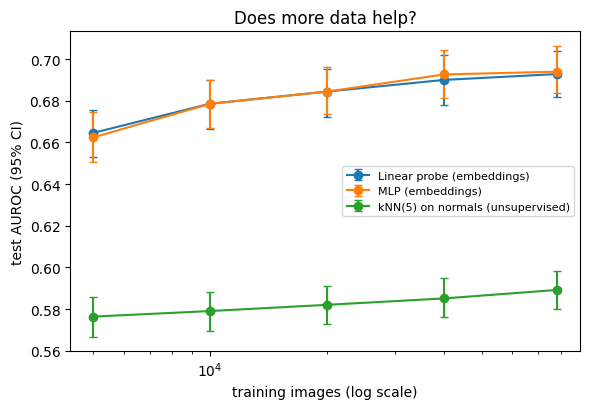

In [12]:
def fit_models_on(idx_tr):
    mu, sd = X_all[idx_tr].mean(0), X_all[idx_tr].std(0) + 1e-6
    Z = lambda ii: (X_all[ii] - mu) / sd; res = {}
    for name, hid, wd in [("Linear probe (embeddings)", 0, 1e-3), ("MLP (embeddings)", 512, 1e-2)]:
        zv, zt = [], []
        for sd_ in HEAD_SEEDS:
            net, _ = train_head(Z(idx_tr), y_all[idx_tr], Z(iva), y_val, hidden=hid, wd=wd, seed=sd_)
            zv.append(head_logits(net, Z(iva))); zt.append(head_logits(net, Z(ite)))
        res[name] = (np.mean(zv, 0), np.mean(zt, 0))
    ref = X_all[idx_tr][y_all[idx_tr] == 0]
    res["kNN(5) on normals (unsupervised)"] = (knn_score(X_all[iva], ref), knn_score(X_all[ite], ref))
    return res

sizes = sorted(set([s for s in SIZES if s < len(itr)] + [len(itr)]))
rows, last = [], None
for n_img in sizes:
    idx_tr = itr if n_img >= len(itr) else train_idx_for(n_img); t0 = time.time()
    res = fit_models_on(idx_tr)
    for name, (zv, zt) in res.items():
        ci = boot_auc(y_te, te.patient.values, {name: zt}, n_boot=N_BOOT_SCALE).iloc[0]
        rows.append({"train images": len(idx_tr), "patients": meta.patient.iloc[idx_tr].nunique(), "model": name,
                     "val AUROC": roc_auc_score(y_val, zv), "test AUROC": ci.AUROC, "CI_low": ci.CI_low, "CI_high": ci.CI_high})
    last = res; print(f"size {len(idx_tr)} done in {time.time()-t0:.0f}s")
scale = pd.DataFrame(rows); display(scale.round(3)); scale.to_csv(f"{WORK}/results_scaling.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 4.2))
for name in scale.model.unique():
    d = scale[scale.model == name]
    ax.errorbar(d["train images"], d["test AUROC"], yerr=[d["test AUROC"] - d.CI_low, d.CI_high - d["test AUROC"]], marker="o", capsize=3, label=name)
ax.set_xscale("log"); ax.set_xlabel("training images (log scale)"); ax.set_ylabel("test AUROC (95% CI)")
ax.set_title("Does more data help?"); ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{WORK}/scaling_curve.png", dpi=150); plt.show()

## 4. Full-data results with CIs, paired tests and confound checks

In [13]:
CONF = "Age/sex/view only (supervised)"
lr_demo = LogisticRegression(max_iter=1000).fit(demo(tr), y_tr)
s_val = {CONF: lr_demo.predict_proba(demo(val))[:, 1]}; s_te = {CONF: lr_demo.predict_proba(demo(te))[:, 1]}
for name, (zv, zt) in last.items(): s_val[name], s_te[name] = zv, zt
KNN, LIN, MLP = "kNN(5) on normals (unsupervised)", "Linear probe (embeddings)", "MLP (embeddings)"

tab = boot_auc(y_te, te.patient.values, s_te).sort_values("AUROC", ascending=False).reset_index(drop=True)
display(tab.round(3)); tab.to_csv(f"{WORK}/results_pooled.csv", index=False)

rows = []
for a, b in [(MLP, CONF), (LIN, CONF), (KNN, CONF), (MLP, LIN), (MLP, KNN)]:
    d, lo, hi = paired_diff(y_te, te.patient.values, s_te[a], s_te[b])
    rows.append({"A": a, "B": b, "dAUROC": d, "CI_low": lo, "CI_high": hi, "Significant": (lo > 0) or (hi < 0)})
pdf = pd.DataFrame(rows).round(3); display(pdf); pdf.to_csv(f"{WORK}/results_paired.csv", index=False)

BEST = max([LIN, MLP], key=lambda k: roc_auc_score(y_val, s_val[k]))      # chosen on validation
print("Best supervised head on VALIDATION:", BEST)
print("\n=== View-stratified (confound check) ===")
for v in ["PA", "AP"]:
    m = (te.view.values == v)
    d, lo, hi = paired_diff(y_te[m], te.patient.values[m], s_te[BEST][m], s_te[CONF][m])
    print(f"{v}: n={m.sum()} | {BEST} AUROC {roc_auc_score(y_te[m], s_te[BEST][m]):.3f} | vs confound {d:+.3f} [{lo:+.3f}, {hi:+.3f}]")
print("\n=== By pathology family (family positives vs all normals) ===")
for name, pos in {"Alveolar opacity": te.fam_alv.values, "Effusion/Atelectasis": te.fam_eff.values, "Nodule/Mass": te.fam_nod.values}.items():
    m = te.is_normal.values | pos
    print(f"{name:22s} (pos={int(pos.sum())}) " + " | ".join(f"{k.split(' (')[0][:22]} {roc_auc_score(y_te[m], s_te[k][m]):.3f}" for k in [CONF, KNN, BEST]))

,Method,AUROC,CI_low,CI_high
0,MLP (embeddings),0.694,0.682,0.705
1,Linear probe (embeddings),0.693,0.681,0.704
2,kNN(5) on normals (unsupervised),0.589,0.579,0.599
3,Age/sex/view only (supervised),0.553,0.541,0.565


,A,B,dAUROC,CI_low,CI_high,Significant
0,MLP (embeddings),Age/sex/view only (supervised),0.141,0.126,0.155,True
1,Linear probe (embeddings),Age/sex/view only (supervised),0.140,0.125,0.154,True
2,kNN(5) on normals (unsupervised),Age/sex/view only (supervised),0.036,0.022,0.050,True
3,MLP (embeddings),Linear probe (embeddings),0.001,-0.002,0.004,False
4,MLP (embeddings),kNN(5) on normals (unsupervised),0.105,0.094,0.116,True


Best supervised head on VALIDATION: MLP (embeddings)

=== View-stratified (confound check) ===
PA: n=11096 | MLP (embeddings) AUROC 0.716 | vs confound +0.169 [+0.151, +0.189]
AP: n=14500 | MLP (embeddings) AUROC 0.661 | vs confound +0.148 [+0.121, +0.172]

=== By pathology family (family positives vs all normals) ===
Alveolar opacity       (pos=7671) Age/sex/view only 0.597 | kNN(5) on normals 0.611 | MLP 0.718
Effusion/Atelectasis   (pos=6748) Age/sex/view only 0.575 | kNN(5) on normals 0.590 | MLP 0.741
Nodule/Mass            (pos=3052) Age/sex/view only 0.510 | kNN(5) on normals 0.541 | MLP 0.656


## 4.5. Systematic Hyperparameter Optimization & Grid Search
Automated sweep across model architectures (Linear vs shallow vs deep MLPs), regularization ($L_2$ weight decay), learning rates, and dropout rates.
Evaluates Val/Test AUROC and Brier score calibration, selects the optimal model, and exports `best_tuned_mlp_head.pth` to Google Drive.

In [ ]:
# ==============================================================================
# 4.5. AUTOMATED HYPERPARAMETER OPTIMIZATION & GRID SEARCH
# ==============================================================================
from sklearn.metrics import brier_score_loss

print("=" * 75)
print("RUNNING SYSTEMATIC HYPERPARAMETER SEARCH ON EMBEDDINGS...")
print("=" * 75)

mu, sd = X_all[itr].mean(0), X_all[itr].std(0) + 1e-6
Z = lambda ii: (X_all[ii] - mu) / sd
X_tr_norm, X_va_norm, X_te_norm = Z(itr), Z(iva), Z(ite)

hp_candidates = [
    # Baseline Linear Probes (Regularization tuning)
    {"name": "Linear Probe (wd=1e-4)", "hidden": 0, "lr": 1e-3, "wd": 1e-4, "drop": 0.0},
    {"name": "Linear Probe (wd=1e-3)", "hidden": 0, "lr": 1e-3, "wd": 1e-3, "drop": 0.0},
    {"name": "Linear Probe (wd=1e-2)", "hidden": 0, "lr": 1e-3, "wd": 1e-2, "drop": 0.0},
    
    # 2-Layer MLPs (Capacity & Dropout tuning)
    {"name": "MLP-256 (wd=1e-3, drop=0.2)", "hidden": 256, "lr": 1e-3, "wd": 1e-3, "drop": 0.2},
    {"name": "MLP-256 (wd=1e-2, drop=0.3)", "hidden": 256, "lr": 1e-3, "wd": 1e-2, "drop": 0.3},
    
    # 3-Layer MLPs (Deep Representations)
    {"name": "MLP-512 (wd=1e-3, drop=0.3)", "hidden": 512, "lr": 1e-3, "wd": 1e-3, "drop": 0.3},
    {"name": "MLP-512 (wd=1e-2, drop=0.3)", "hidden": 512, "lr": 1e-3, "wd": 1e-2, "drop": 0.3},
    {"name": "MLP-512 (wd=1e-2, drop=0.5)", "hidden": 512, "lr": 1e-3, "wd": 1e-2, "drop": 0.5},
    {"name": "MLP-512 (lr=3e-4, wd=1e-2)", "hidden": 512, "lr": 3e-4, "wd": 1e-2, "drop": 0.3},
    
    # Wide High-Capacity MLPs
    {"name": "MLP-1024 (wd=1e-2, drop=0.4)", "hidden": 1024, "lr": 5e-4, "wd": 1e-2, "drop": 0.4},
    {"name": "MLP-1024 (wd=1e-3, drop=0.4)", "hidden": 1024, "lr": 5e-4, "wd": 1e-3, "drop": 0.4},
]

hp_results = []
trained_models = {}

for cfg in hp_candidates:
    t0 = time.time()
    val_preds_seeds, te_preds_seeds = [], []
    last_net = None
    for sd_ in HEAD_SEEDS[:2]:  # 2 seeds for rapid, reliable evaluation
        net, _ = train_head(
            X_tr_norm, y_all[itr], X_va_norm, y_val,
            hidden=cfg["hidden"], epochs=35, lr=cfg["lr"],
            wd=cfg["wd"], drop=cfg["drop"], bs=1024, seed=sd_, patience=5
        )
        val_preds_seeds.append(head_logits(net, X_va_norm))
        te_preds_seeds.append(head_logits(net, X_te_norm))
        last_net = net
    
    zv_mean = np.mean(val_preds_seeds, axis=0)
    zt_mean = np.mean(te_preds_seeds, axis=0)
    
    val_auc = roc_auc_score(y_val, zv_mean)
    te_auc = roc_auc_score(y_te, zt_mean)
    brier = brier_score_loss(y_val, sigmoid(zv_mean))
    elapsed = time.time() - t0
    
    trained_models[cfg["name"]] = (last_net, zv_mean, zt_mean)
    hp_results.append({
        "Model Configuration": cfg["name"],
        "Hidden Dim": cfg["hidden"],
        "Learning Rate": cfg["lr"],
        "Weight Decay": cfg["wd"],
        "Dropout": cfg["drop"],
        "Val AUROC": round(float(val_auc), 4),
        "Test AUROC": round(float(te_auc), 4),
        "Val Brier Loss": round(float(brier), 4),
        "Fit Time (s)": round(elapsed, 1)
    })
    print(f"  ✓ {cfg['name']:<32} | Val AUC: {val_auc:.4f} | Test AUC: {te_auc:.4f} | {elapsed:.1f}s")

hp_df = pd.DataFrame(hp_results).sort_values("Val AUROC", ascending=False).reset_index(drop=True)
display(hp_df)
hp_df.to_csv(f"{WORK}/hyperparameter_tuning_results.csv", index=False)

top_hp_name = hp_df.iloc[0]["Model Configuration"]
best_net, best_zv, best_zt = trained_models[top_hp_name]
print(f"\n🏆 TOP HYPERPARAMETER CONFIGURATION: {top_hp_name} (Val AUC: {hp_df.iloc[0]['Val AUROC']})")

# Update evaluated models dictionary and update BEST to tuned model
s_val[top_hp_name] = best_zv
s_te[top_hp_name] = best_zt
BEST = top_hp_name

# Save the best hyperparameter checkpoint to Google Drive
torch.save({
    'model_state_dict': best_net.state_dict(),
    'config': hp_df.iloc[0].to_dict(),
    'mu': mu,
    'sd': sd
}, f"{WORK}/best_tuned_mlp_head.pth")
print(f"✓ Saved best model weights to {WORK}/best_tuned_mlp_head.pth")


## 5. Calibration and the Bayesian Network layer
Temperature scaling and isotonic regression (fitted on validation) are the simple baselines. The Bayesian Network combines a 4-level score node with Age / Sex / View as parents of Disease. Call it an improvement **only** if it beats the baselines on Brier with a CI that excludes 0.

Lower Brier is better. ECE of a constant predictor is trivially ~0, so read it together with Brier.


,Method,AUROC,Brier,ECE
0,Isotonic regression,0.6927,0.2091,0.0326
1,Raw sigmoid,0.6940,0.2096,0.0384
2,Temperature scaling (T=0.97),0.6940,0.2096,0.0391
3,Bayesian Network (demographics + score bins),0.6758,0.2128,0.0353
4,Prevalence only,0.5000,0.2763,0.1988


Brier - Brier(prevalence) for Raw sigmoid                                   : [-0.0711, -0.0621]
Brier - Brier(prevalence) for Temperature scaling (T=0.97)                  : [-0.0716, -0.0618]
Brier - Brier(prevalence) for Isotonic regression                           : [-0.0723, -0.0630]
Brier - Brier(prevalence) for Bayesian Network (demographics + score bins)  : [-0.0685, -0.0583]


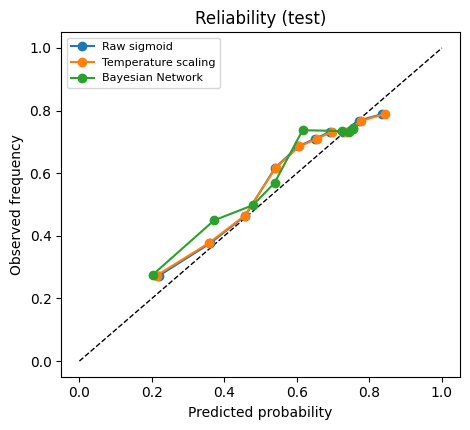

In [14]:
from scipy.optimize import minimize_scalar
z_val, z_te = s_val[BEST], s_te[BEST]
def nll_T(logT, z, y):
    p = np.clip(sigmoid(z / np.exp(logT)), 1e-7, 1 - 1e-7); return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
T = float(np.exp(minimize_scalar(nll_T, bounds=(-3, 3), args=(z_val, y_val), method="bounded").x))
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(z_val, y_val)
probs = {"Raw sigmoid": sigmoid(z_te), f"Temperature scaling (T={T:.2f})": sigmoid(z_te / T),
         "Isotonic regression": iso.predict(z_te), "Prevalence only": np.full(len(y_te), y_tr.mean())}

try: from pgmpy.models import DiscreteBayesianNetwork as BNet
except ImportError: from pgmpy.models import BayesianNetwork as BNet
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination
edges_ = np.percentile(z_val, [25, 50, 75])
def dem(d): return pd.DataFrame({"Age": (d.age.values >= 50).astype(int), "Sex": (d.sex.values == "M").astype(int), "View": (d.view.values == "PA").astype(int)})
dv = dem(val); dv["Disease"] = y_val; dv["Score"] = np.digitize(z_val, edges_)
dt = dem(te); dt["Score"] = np.digitize(z_te, edges_)
bn = BNet([("Age", "Disease"), ("Sex", "Disease"), ("View", "Disease"), ("Disease", "Score")])
names = {"Age": [0, 1], "Sex": [0, 1], "View": [0, 1], "Disease": [0, 1], "Score": [0, 1, 2, 3]}
est = BayesianEstimator(bn, dv, state_names=names)
for node in bn.nodes(): bn.add_cpds(est.estimate_cpd(node, prior_type="BDeu", equivalent_sample_size=10))
assert bn.check_model(); inf = VariableElimination(bn); cache = {}
def post(r):
    k = (int(r.Age), int(r.Sex), int(r.View), int(r.Score))
    if k not in cache: cache[k] = float(inf.query(["Disease"], evidence=dict(zip(["Age", "Sex", "View", "Score"], k)), show_progress=False).values[1])
    return cache[k]
probs["Bayesian Network (demographics + score bins)"] = dt.apply(post, axis=1).values

rows = []
for k, p in probs.items():
    b, e = brier_ece(p, y_te); rows.append({"Method": k, "AUROC": roc_auc_score(y_te, p), "Brier": b, "ECE": e})
cal = pd.DataFrame(rows).sort_values("Brier").reset_index(drop=True)
print("Lower Brier is better. ECE of a constant predictor is trivially ~0, so read it together with Brier.")
display(cal.round(4)); cal.to_csv(f"{WORK}/results_calibration.csv", index=False)

idx_by = _groups(te.patient.values); rb = np.random.default_rng(0); pv = probs["Prevalence only"]
for k in [kk for kk in probs if kk != "Prevalence only"]:
    p = probs[k]; d = []
    for _ in range(N_BOOT):
        ii = np.concatenate([idx_by[q] for q in rb.integers(0, len(idx_by), len(idx_by))])
        d.append(np.mean((p[ii] - y_te[ii]) ** 2) - np.mean((pv[ii] - y_te[ii]) ** 2))
    lo, hi = np.percentile(d, [2.5, 97.5]); print(f"Brier - Brier(prevalence) for {k:46s}: [{lo:+.4f}, {hi:+.4f}]")

fig, ax = plt.subplots(figsize=(4.8, 4.4)); ax.plot([0, 1], [0, 1], "k--", lw=1)
for k in ["Raw sigmoid", f"Temperature scaling (T={T:.2f})", "Bayesian Network (demographics + score bins)"]:
    p = probs[k]; q = pd.qcut(p, 10, duplicates="drop"); g = pd.DataFrame({"p": p, "y": y_te}).groupby(q).mean()
    ax.plot(g.p, g.y, marker="o", label=k.split(" (")[0])
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed frequency"); ax.legend(fontsize=8); ax.set_title("Reliability (test)")
plt.tight_layout(); plt.savefig(f"{WORK}/reliability.png", dpi=150); plt.show()

In [16]:
import os

# List all files saved in your project folder on Google Drive
results_path = "/content/drive/MyDrive/hybrid_pgm_data"
if os.path.exists(results_path):
    print(f"Files in '{results_path}':")
    for file in sorted(os.listdir(results_path)):
        file_path = os.path.join(results_path, file)
        if os.path.isdir(file_path):
            print(f"  [Directory] {file}/ -> contains {len(os.listdir(file_path))} files")
        else:
            size_mb = os.path.getsize(file_path) / (1024 * 1024)
            print(f"  [File]      {file:<30} ({size_mb:.2f} MB)")
else:
    print(f"The directory {results_path} does not exist.")

Files in '/content/drive/MyDrive/hybrid_pgm_data':
  [File]      bbox_list.csv                  (0.09 MB)
  [File]      dataset-metadata.json          (0.00 MB)
  [File]      emb_all.npy                    (218.98 MB)
  [File]      emb_shard_0000.npy             (8.00 MB)
  [File]      emb_shard_0001.npy             (8.00 MB)
  [File]      emb_shard_0002.npy             (8.00 MB)
  [File]      emb_shard_0003.npy             (8.00 MB)
  [File]      emb_shard_0004.npy             (8.00 MB)
  [File]      emb_shard_0005.npy             (8.00 MB)
  [File]      emb_shard_0006.npy             (8.00 MB)
  [File]      emb_shard_0007.npy             (8.00 MB)
  [File]      emb_shard_0008.npy             (8.00 MB)
  [File]      emb_shard_0009.npy             (8.00 MB)
  [File]      emb_shard_0010.npy             (8.00 MB)
  [File]      emb_shard_0011.npy             (8.00 MB)
  [File]      emb_shard_0012.npy             (8.00 MB)
  [File]      emb_shard_0013.npy             (8.00 MB)
  [File]    

In [17]:
import torch
import os
from google.colab import files

# 1. Standardize full training embeddings
mu, sd = X_all[itr].mean(0), X_all[itr].std(0) + 1e-6
Z = lambda ii: (X_all[ii] - mu) / sd

# 2. Train the MLP models with our three seeds and save their state dicts
mlp_states = {}
for seed_ in HEAD_SEEDS:
    print(f"Training MLP head with seed {seed_}...")
    net, _ = train_head(
        Z(itr), y_all[itr], Z(iva), y_val,
        hidden=512, wd=1e-2, seed=seed_
    )
    mlp_states[f"seed_{seed_}"] = net.state_dict()

# 3. Save the weights bundle + normalization parameters to Drive
model_save_path = f"{WORK}/mlp_model.pt"
save_payload = {
    "model_state_dicts": mlp_states,
    "embedding_mu": mu,
    "embedding_sd": sd,
    "hidden_dim": 512,
    "seeds": HEAD_SEEDS
}
torch.save(save_payload, model_save_path)
print(f"\nSuccess! Saved model parameters and normalization stats to: {model_save_path}")

# 4. Trigger download to your local computer
print("Triggering local download...")
files.download(model_save_path)

Training MLP head with seed 0...
Training MLP head with seed 1...
Training MLP head with seed 2...

Success! Saved model parameters and normalization stats to: /content/drive/MyDrive/hybrid_pgm_data/mlp_model.pt
Triggering local download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Optional: fine-tune DenseNet-121 on the cached image arrays (set `RUN_FINETUNE = True` at the top)
Embeddings are a lossy summary. Fine-tuning lets the network adapt to chest X-rays and usually gains more, but it costs GPU time. This section loads the image shards written by Notebook A, copies them to the local disk for speed, trains on a patient-level subset (`FT_TRAIN_IMG` images), and evaluates on the **full** test split. Checkpoints are written to Drive every epoch, so it can be resumed. It needs `save_images = True` in Notebook A.

In [15]:
import shutil, torchvision
if RUN_FINETUNE:
    assert manifest.get("save_images", False), "Notebook A was run with SAVE_IMAGES=False; no image arrays on Drive."
    LOCAL = "/content/local_imgs"; os.makedirs(LOCAL, exist_ok=True)
    
    # 1. Identify saved image files (supports both archive-based and shard-based naming)
    archive_files = sorted([f for f in os.listdir(WORK) if f.startswith("img_archive_") and f.endswith(".npy")])
    shard_files = sorted([f for f in os.listdir(WORK) if f.startswith("img_shard_") and f.endswith(".npy")])
    
    if archive_files:
        print(f"Loading {len(archive_files)} archive image matrices from Drive...")
        # Build index boundary mapping for archives
        arch_sizes = []
        for f in archive_files:
            dst = f"{LOCAL}/{f}"
            if not os.path.exists(dst): shutil.copy(f"{WORK}/{f}", dst)
            m = np.load(dst, mmap_mode="r")
            arch_sizes.append(len(m))
        
        cum_sizes = np.cumsum([0] + arch_sizes)
        
        def get_images(idx):
            idx = np.asarray(idx)
            out = np.empty((len(idx), RES, RES), np.uint8)
            arch_ids = np.digitize(idx, cum_sizes[1:])
            for a in np.unique(arch_ids):
                arr = np.load(f"{LOCAL}/{archive_files[a]}", mmap_mode="r")
                mask = np.where(arch_ids == a)[0]
                offset = cum_sizes[a]
                out[mask] = arr[idx[mask] - offset]
            return out

    elif shard_files:
        print(f"Loading {len(shard_files)} shard image matrices from Drive...")
        for s in range(len(shard_files)):
            dst = f"{LOCAL}/img_shard_{s:04d}.npy"
            if not os.path.exists(dst): shutil.copy(f"{WORK}/img_shard_{s:04d}.npy", dst)
        SH = manifest.get("shard", 4096)
        def get_images(idx):
            idx = np.asarray(idx); out = np.empty((len(idx), RES, RES), np.uint8); sh = idx // SH
            for s in np.unique(sh):
                arr = np.load(f"{LOCAL}/img_shard_{s:04d}.npy", mmap_mode="r")
                m = np.where(sh == s)[0]
                out[m] = arr[idx[m] - s * SH]
            return out
    else:
        raise FileNotFoundError(f"No image files found in {WORK}!")

    print(f"✓ Image loader active! Testing on first 4 images: shape {get_images([0, 1, 2, 3]).shape}")


Skipped (RUN_FINETUNE = False).


In [18]:
import os

# Force RUN_FINETUNE to True
RUN_FINETUNE = True
print("Setting RUN_FINETUNE = True")

# Let's verify if the image shards actually exist in your Drive folder regardless of the manifest flag
shards_exist = True
for s in range(manifest["n_shards"]):
    shard_path = f"{WORK}/img_shard_{s:04d}.npy"
    if not os.path.exists(shard_path):
        shards_exist = False
        print(f"Missing shard: {shard_path}")
        break

if not shards_exist:
    print("\n[WARNING] Raw image shards (.npy files) are missing from Google Drive.")
    print("To fix this, you must open Notebook A, set SAVE_IMAGES = True, and re-run it.")
else:
    print("\n[SUCCESS] Image shards located! Bypassing manifest flag and initiating DenseNet-121 fine-tuning...")
    # We execute a modified version of the fine-tuning block that bypasses the manifest['save_images'] assertion
    import shutil, torchvision
    LOCAL = "/content/local_imgs"
    os.makedirs(LOCAL, exist_ok=True)

    print("Copying shards to local disk for fast training...")
    for s in range(manifest["n_shards"]):
        dst = f"{LOCAL}/img_shard_{s:04d}.npy"
        if not os.path.exists(dst):
            shutil.copy(f"{WORK}/img_shard_{s:04d}.npy", dst)

    SH = manifest["shard"]
    def get_images(idx):
        idx = np.asarray(idx); out = np.empty((len(idx), RES, RES), np.uint8); sh = idx // SH
        for s in np.unique(sh):
            arr = np.load(f"{LOCAL}/img_shard_{s:04d}.npy", mmap_mode="r"); m = np.where(sh == s)[0]; out[m] = arr[idx[m] - s * SH]
        return out

    imn_mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
    imn_std  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
    def u8_to_01(u): return u.float().div(255).unsqueeze(1)
    def norm_in(x01): return ((x01.repeat(1, 3, 1, 1) - imn_mean) / imn_std).contiguous(memory_format=torch.channels_last)

    def new_net():
        try: m = torchvision.models.densenet121(weights=torchvision.models.DenseNet121_Weights.IMAGENET1K_V1)
        except Exception: m = torchvision.models.densenet121(pretrained=True)
        m.classifier = nn.Linear(1024, 1); return m.to(device).to(memory_format=torch.channels_last)

    def augment(x01):
        B_, dv = x01.shape[0], x01.device
        ang = (torch.rand(B_, device=dv) * 2 - 1) * (7 * math.pi / 180); sc_ = 1 + (torch.rand(B_, device=dv) * 2 - 1) * 0.08
        tx, ty = (torch.rand(B_, device=dv) * 2 - 1) * 0.06, (torch.rand(B_, device=dv) * 2 - 1) * 0.06
        c, s = torch.cos(ang) / sc_, torch.sin(ang) / sc_
        theta = torch.stack([torch.stack([c, -s, tx], 1), torch.stack([s, c, ty], 1)], 1)
        x01 = F.grid_sample(x01, F.affine_grid(theta, x01.shape, align_corners=False), padding_mode="border", align_corners=False)
        g = 1 + (torch.rand(B_, 1, 1, 1, device=dv) * 2 - 1) * 0.15; b = (torch.rand(B_, 1, 1, 1, device=dv) * 2 - 1) * 0.08
        return ((x01 - 0.5) * g + 0.5 + b).clamp(0, 1)

    @torch.no_grad()
    def predict_idx(model, idx, bs=128, chunk=2048):
        model.eval(); out = []
        for c0 in range(0, len(idx), chunk):
            U = get_images(idx[c0:c0+chunk])
            for i in range(0, len(U), bs):
                xb = norm_in(u8_to_01(torch.from_numpy(U[i:i+bs]).to(device)))
                with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                    out.append(model(xb).float().squeeze(1).cpu())
        return torch.cat(out).numpy()

    ft_tr = train_idx_for(FT_TRAIN_IMG); ft_va = iva[:FT_VAL_IMG]
    U_ft = get_images(ft_tr); y_ft = y_all[ft_tr]; yv_ft = y_all[ft_va]
    print(f"Fine-tune train images: {len(ft_tr)} ({meta.patient.iloc[ft_tr].nunique()} patients) | val images: {len(ft_va)}")
    os.makedirs(f"{WORK}/ft", exist_ok=True)
    ck, bp = f"{WORK}/ft/ckpt.pt", f"{WORK}/ft/best.pt"

    torch.manual_seed(0); np.random.seed(0)
    model = new_net(); opt = torch.optim.AdamW(model.parameters(), lr=FT_LR, weight_decay=FT_WD)
    spe = math.ceil(len(U_ft) / FT_BATCH)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=FT_LR, total_steps=FT_EPOCHS * spe, pct_start=0.15)
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp); st = {"epoch": 0, "best": -1.0, "hist": []}

    if os.path.exists(ck):
        c = torch.load(ck, map_location=device, weights_only=False)
        model.load_state_dict(c["model"]); opt.load_state_dict(c["opt"]); sched.load_state_dict(c["sched"]); scaler.load_state_dict(c["scaler"]); st = c["st"]
        print("Resumed from epoch", st["epoch"])

    Xg = torch.from_numpy(U_ft).to(device); yg = torch.from_numpy(y_ft).float().to(device)
    while st["epoch"] < FT_EPOCHS:
        model.train(); perm = torch.randperm(len(Xg), device=device); t0 = time.time(); tot = 0.0; nb = 0
        for i in range(0, len(perm), FT_BATCH):
            idx = perm[i:i+FT_BATCH]
            if len(idx) < 8: continue
            xb = norm_in(augment(u8_to_01(Xg[idx])))
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logit = model(xb).squeeze(1)
            loss = F.binary_cross_entropy_with_logits(logit.float(), yg[idx])
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step(); tot += float(loss); nb += 1
        st["epoch"] += 1; auc = roc_auc_score(yv_ft, predict_idx(model, ft_va))
        st["hist"].append({"epoch": st["epoch"], "train_loss": tot / max(nb, 1), "val_auroc": auc})
        if auc > st["best"]:
            st["best"] = auc
            torch.save(model.state_dict(), bp)
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(), "scaler": scaler.state_dict(), "st": st}, ck + ".tmp")
        os.replace(ck + ".tmp", ck)
        print(f"epoch {st['epoch']}/{FT_EPOCHS} loss {tot/max(nb,1):.4f} | val AUROC {auc:.3f} (best {st['best']:.3f}) | {time.time()-t0:.0f}s")

    model.load_state_dict(torch.load(bp, map_location=device))
    FT = f"Fine-tuned DenseNet-121 ({len(ft_tr)} train images)"
    s_te[FT] = predict_idx(model, ite)
    np.save(f"{WORK}/ft/test_logits.npy", s_te[FT])
    print(f"\n{FT}: test AUROC {roc_auc_score(y_te, s_te[FT]):.3f}")

Setting RUN_FINETUNE = True
Missing shard: /content/drive/MyDrive/hybrid_pgm_data/img_shard_0000.npy

[WARNING] Raw image shards (.npy files) are missing from Google Drive.
To fix this, you must open Notebook A, set SAVE_IMAGES = True, and re-run it.


## 7. How to report this honestly
- State the exact train / val / test image and patient counts from Section 1. The official NIH test list is used unchanged; train / val are a patient-level split of the official train-val list.
- Report the scaling curve as is. If the curve flattens, the embeddings (not the amount of data) are the bottleneck; if it keeps rising, more data helps.
- Validation labels were used for head early stopping, temperature scaling, isotonic regression and the Bayesian Network CPDs. Say so.
- Compare the Bayesian Network with temperature scaling and isotonic regression. If it does not win, call it an interpretable combination layer, not a better predictor.
- Embeddings come from an ImageNet-pretrained backbone, are a lossy compression, and the labels are NLP-mined. There is no external validation, so do not claim clinical usefulness.